In [2]:
import json, glob, os, random
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import cv2

BASE   = r"C:\Users\arijk\Desktop\DriveSight\DriveSight\data\dataset"
IMG_D  = os.path.join(BASE, "images", "train")
LAB_D  = os.path.join(BASE, "labels_json", "train")
OUT_D  = r"C:\Users\arijk\Desktop\DriveSight\DriveSight\docs"
os.makedirs(OUT_D, exist_ok=True)

In [3]:
rows, scenes = [], []
for p in glob.glob(os.path.join(LAB_D, "*.json")):
    d = json.load(open(p))
    name, a = d["name"], d.get("attributes", {})
    scenes.append({"video": name, "weather": a.get("weather"),
                   "scene": a.get("scene"), "timeofday": a.get("timeofday")})
    for fr in d.get("frames", []):
        for o in fr.get("objects", []):
            if "box2d" not in o:
                continue
            b, oa = o["box2d"], o.get("attributes", {})
            rows.append({"video": name, "category": o["category"],
                         "x1": b["x1"], "y1": b["y1"], "x2": b["x2"], "y2": b["y2"],
                         "occluded": oa.get("occluded"), "truncated": oa.get("truncated")})

df, sc = pd.DataFrame(rows), pd.DataFrame(scenes)
df["area"] = (df.x2 - df.x1) * (df.y2 - df.y1)

print("Images :", len(sc), "| boîtes :", len(df), "| moyenne :", round(len(df)/len(sc), 1), "par image")
print("\nClasses :\n", df["category"].value_counts())
print("\nOccluded :", df["occluded"].mean().round(3), "| Truncated :", df["truncated"].mean().round(3))
print("Boîtes < 300 px² :", (df.area < 300).sum(), "| > 250000 px² :", (df.area > 250000).sum())
for c in ["weather", "scene", "timeofday"]:
    print(f"\n{c} :\n", sc[c].value_counts())


Images : 2500 | boîtes : 48961 | moyenne : 19.6 par image

Classes :
 category
car              26850
traffic sign      9098
traffic light     6225
person            4110
truck             1383
bus                543
bike               344
rider              228
motor              160
train               20
Name: count, dtype: int64

Occluded : 0.504 | Truncated : 0.073
Boîtes < 300 px² : 12095 | > 250000 px² : 79

weather :
 weather
clear            859
overcast         528
undefined        430
partly cloudy    296
snowy            202
rainy            183
foggy              2
Name: count, dtype: int64

scene :
 scene
city street     1493
highway          589
residential      385
parking lot       19
undefined         10
tunnel             3
gas stations       1
Name: count, dtype: int64

timeofday :
 timeofday
daytime      2115
dawn/dusk     281
night         100
undefined       4
Name: count, dtype: int64



Sorties dans C:\Users\arijk\Desktop\DriveSight\DriveSight\docs


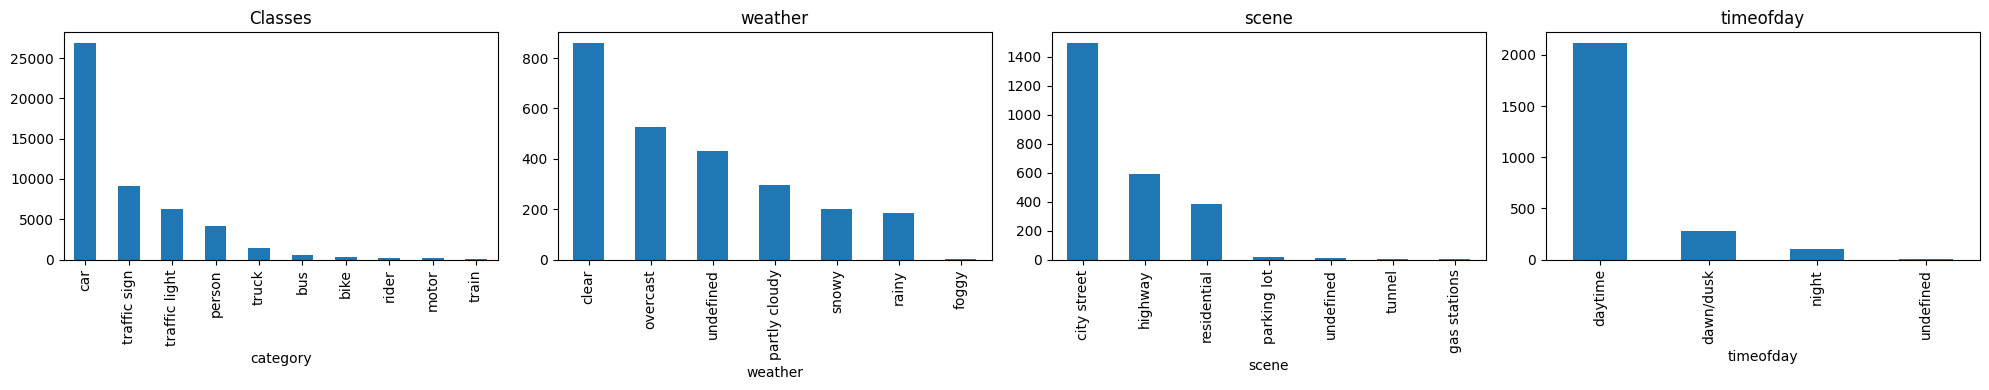

In [4]:
# graphiques
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
df["category"].value_counts().plot.bar(ax=ax[0], title="Classes")
for i, c in enumerate(["weather", "scene", "timeofday"], 1):
    sc[c].value_counts().plot.bar(ax=ax[i], title=c)
plt.tight_layout(); plt.savefig(os.path.join(OUT_D, "eda_distributions.png"), dpi=120)

# image exemple avec boîtes
name = random.choice(sc["video"].tolist())
img = cv2.imread(os.path.join(IMG_D, name + ".jpg"))
for _, r in df[df.video == name].iterrows():
    cv2.rectangle(img, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), (0, 0, 255), 2)
    cv2.putText(img, r.category, (int(r.x1), int(r.y1) - 3),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
cv2.imwrite(os.path.join(OUT_D, "eda_sample.jpg"), img)
print("\nSorties dans", OUT_D)